In [1]:
# ============================================================
# FE5108 Final Project - Part 1
# Question 1C: Benefits of Factor Diversification
# ============================================================

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

# Locate the repository root
current_dir = Path.cwd().resolve()

ROOT = next(
    (
        p for p in [current_dir, *current_dir.parents]
        if (p / "src" / "config.py").exists()
    ),
    None
)

if ROOT is None:
    raise FileNotFoundError("Project root not found.")

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src import config, utils

config.apply_style()

print("Project root:", ROOT)
print("MSCI data file exists:", config.FILE_FF_MSCI.exists())

Project root: /Users/zhangjiaxin/Desktop/fe5018-final
MSCI data file exists: True


In [2]:
# Step 2: Inspect the MSCI factor index data

raw_msci = pd.read_excel(
    config.FILE_FF_MSCI,
    sheet_name=config.SHEET_MSCI,
    header=None
)

print("MSCI data shape:", raw_msci.shape)

print("\nFirst 18 rows:")
display(raw_msci.head(18))

print("\nLast 8 rows:")
display(raw_msci.tail(8))

MSCI data shape: (370, 6)

First 18 rows:


,0,1,2,3,4,5
0,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN
2,Index Level :,Gross,NaN,NaN,NaN,NaN
3,Currency :,USD,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,NaN,NaN,NaN
6,Date,USA Standard (Large+Mid Cap),USA VALUE Standard (Large+Mid Cap),USA MINIMUM VOLATILITY (USD) Standard (Large+M...,USA EQUAL WEIGHTED Standard (Large+Mid Cap),USA MOMENTUM Standard (Large+Mid Cap)
7,"Dec 30, 1994","1,182.011","1,756.476",387.308,413.761,122.578
8,"Jan 31, 1995","1,214.883","1,808.731",396.010,423.714,124.135
9,"Feb 28, 1995","1,263.074","1,883.852",410.371,442.930,129.288



Last 8 rows:


,0,1,2,3,4,5
362,None of the MSCI Parties makes any representat...,NaN,NaN,NaN,NaN,NaN
363,"entity from any use of this information, and t...",NaN,NaN,NaN,NaN,NaN
364,None of the MSCI Parties makes any express or ...,NaN,NaN,NaN,NaN,NaN
365,merchantability or fitness for a particular pu...,NaN,NaN,NaN,NaN,NaN
366,in no event shall any of the MSCI Parties have...,NaN,NaN,NaN,NaN,NaN
367,damages (including lost profits) even if notif...,NaN,NaN,NaN,NaN,NaN
368,and all other service marks referred to herein...,NaN,NaN,NaN,NaN,NaN
369,are the exclusive property of MSCI and may not...,NaN,NaN,NaN,NaN,NaN


In [3]:

# Step 3: Clean MSCI index levels and calculate monthly returns

msci = raw_msci.iloc[7:].copy()

msci.columns = [
    "Date",
    "Market",
    "Value",
    "MinVol",
    "EqualWeight",
    "Momentum"
]

# Keep rows containing valid calendar dates
msci["Date"] = pd.to_datetime(
    msci["Date"],
    errors="coerce"
)

msci = msci.dropna(subset=["Date"])

# Convert dates to monthly periods
msci = msci.set_index("Date")
msci = utils.to_monthly_index(msci)

# Convert index levels to decimal monthly returns
msci_returns = utils.levels_to_returns(msci)

# Select the assignment's analysis period
msci_returns = utils.select_period(
    msci_returns,
    "1C"
)

print("MSCI monthly returns:")
display(msci_returns.head())

print("\nSample period:")
print(msci_returns.index.min(), "to", msci_returns.index.max())

print("\nNumber of monthly observations:")
print(len(msci_returns))

print("\nMissing observations:")
display(msci_returns.isna().sum())


MSCI monthly returns:


,Market,Value,MinVol,EqualWeight,Momentum
month,,,,,
1995-01,0.027810,0.029750,0.022468,0.024055,0.012702
1995-02,0.039667,0.041532,0.036264,0.045351,0.041511
1995-03,0.027036,0.026375,0.029685,0.027659,0.045936
1995-04,0.031632,0.034503,0.027145,0.022943,0.043127
1995-05,0.039288,0.040906,0.033892,0.037515,0.037311



Sample period:
1995-01 to 2023-07

Number of monthly observations:
343

Missing observations:


Market         0
Value          0
MinVol         0
EqualWeight    0
Momentum       0
dtype: int64

In [4]:

# Step 4: Validate MSCI monthly return calculations

expected_jan95 = 1214.883 / 1182.011 - 1

actual_jan95 = msci_returns.loc[
    "1995-01", "Market"
]

assert abs(actual_jan95 - expected_jan95) < 1e-10

assert msci_returns.index.min() == pd.Period(
    "1995-01", freq="M"
)

assert msci_returns.index.max() == pd.Period(
    "2023-07", freq="M"
)

assert len(msci_returns) == 343
assert msci_returns.index.is_unique
assert msci_returns.notna().all().all()

print("All MSCI data validation checks passed.")
print(f"MSCI USA Jan 1995 return: {actual_jan95:.4%}")

All MSCI data validation checks passed.
MSCI USA Jan 1995 return: 2.7810%


In [5]:
# Step 5: Construct the equally weighted multi-factor portfolio

factor_columns = [
    "Value",
    "MinVol",
    "EqualWeight",
    "Momentum"
]

msci_returns["MultiFactor"] = (
    msci_returns[factor_columns].mean(axis=1)
)

display(msci_returns.head())

# Verify the first monthly multi-factor return
expected_jan95 = (
    msci_returns.loc["1995-01", factor_columns].sum() / 4
)

assert abs(
    msci_returns.loc["1995-01", "MultiFactor"] - expected_jan95
) < 1e-12

print("Multi-factor portfolio construction passed.")

,Market,Value,MinVol,EqualWeight,Momentum,MultiFactor
month,,,,,,
1995-01,0.027810,0.029750,0.022468,0.024055,0.012702,0.022244
1995-02,0.039667,0.041532,0.036264,0.045351,0.041511,0.041165
1995-03,0.027036,0.026375,0.029685,0.027659,0.045936,0.032414
1995-04,0.031632,0.034503,0.027145,0.022943,0.043127,0.031929
1995-05,0.039288,0.040906,0.033892,0.037515,0.037311,0.037406


Multi-factor portfolio construction passed.


In [6]:
# Step 6: Load and align the monthly risk-free rate

raw_ff = pd.read_excel(
    config.FILE_FF_MSCI,
    sheet_name=config.SHEET_FF3,
    header=None
)

ff = raw_ff.iloc[4:].copy()
ff.columns = ["Date", "Mkt-RF", "SMB", "HML", "RF"]

# Keep monthly observations only
date_text = ff["Date"].astype(str).str.strip()
mask = date_text.str.fullmatch(r"\d{6}(\.0)?")
ff = ff.loc[mask].copy()

ff["Date"] = ff["Date"].astype(float).astype(int).astype(str)
ff = ff.set_index("Date")

ff = ff.apply(pd.to_numeric, errors="coerce")
ff = utils.pct_to_decimal(ff)
ff = utils.to_monthly_index(ff)

# Select the same period as the MSCI returns
rf = utils.select_period(ff["RF"], "1C")

assert rf.index.equals(msci_returns.index)
assert rf.notna().all()

print("Risk-free sample:", rf.index.min(), "to", rf.index.max())
print("Risk-free observations:", len(rf))

display(rf.head().to_frame("RF"))

Risk-free sample: 1995-01 to 2023-07
Risk-free observations: 343


,RF
month,
1995-01,0.0042
1995-02,0.0040
1995-03,0.0046
1995-04,0.0044
1995-05,0.0054


In [7]:
# Step 7: Calculate annualized performance statistics

performance = []

for strategy in msci_returns.columns:
    returns = msci_returns[strategy]

    performance.append({
        "Strategy": strategy,
        "Annualized Return (%)": (
            utils.annualized_return(
                returns, method="arithmetic"
            ) * 100
        ),
        "Annualized Volatility (%)": (
            utils.annualized_volatility(returns) * 100
        ),
        "Sharpe Ratio": utils.sharpe_ratio(
            returns, rf, method="arithmetic"
        )
    })

# Include the risk-free investment as a separate row
performance.append({
    "Strategy": "RiskFree",
    "Annualized Return (%)": (
        utils.annualized_return(
            rf, method="arithmetic"
        ) * 100
    ),
    "Annualized Volatility (%)": (
        utils.annualized_volatility(rf) * 100
    ),
    "Sharpe Ratio": float("nan")
})

performance_df = pd.DataFrame(performance)

print("===== QUESTION 1C: PERFORMANCE COMPARISON =====")
display(performance_df.round(4))

===== QUESTION 1C: PERFORMANCE COMPARISON =====


,Strategy,Annualized Return (%),Annualized Volatility (%),Sharpe Ratio
0,Market,11.2171,15.4368,0.5865
1,Value,9.8737,15.2667,0.5050
2,MinVol,10.4215,12.0923,0.6829
3,EqualWeight,11.8056,17.1328,0.5627
4,Momentum,13.3752,16.3409,0.6861
5,MultiFactor,11.3690,14.4014,0.6392
6,RiskFree,2.1642,0.6102,NaN


In [8]:
# Step 8: Validate and save performance results

assert len(performance_df) == 7
assert performance_df["Strategy"].is_unique
assert performance_df.loc[
    performance_df["Strategy"] != "RiskFree",
    "Sharpe Ratio"
].notna().all()

monthly_path = utils.save_table(
    msci_returns,
    "tab_1C_monthly_returns"
)

performance_path = utils.save_table(
    performance_df.set_index("Strategy"),
    "tab_1C_performance"
)

print("Monthly returns saved to:", monthly_path)
print("Performance table saved to:", performance_path)

Monthly returns saved to: /Users/zhangjiaxin/Desktop/fe5018-final/output/tables/tab_1C_monthly_returns.csv
Performance table saved to: /Users/zhangjiaxin/Desktop/fe5018-final/output/tables/tab_1C_performance.csv


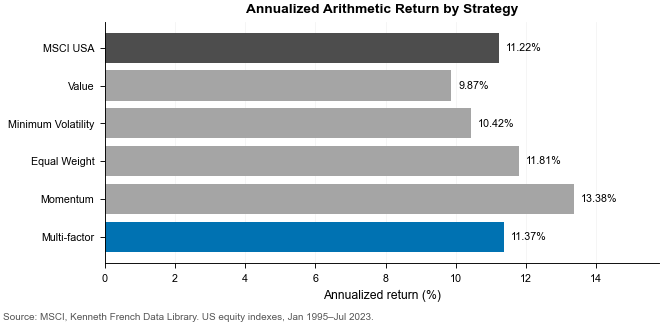

Saved: /Users/zhangjiaxin/Desktop/fe5018-final/output/figures/fig_1C_return.png


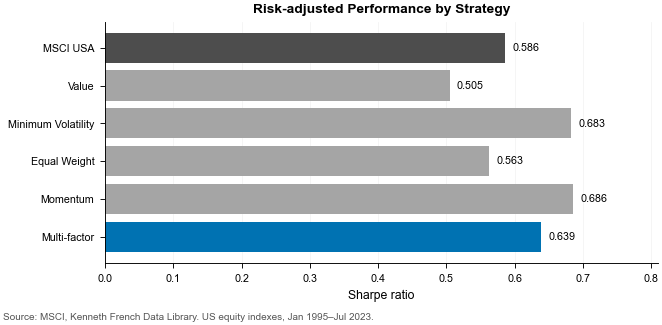

Saved: /Users/zhangjiaxin/Desktop/fe5018-final/output/figures/fig_1C_sharpe.png


In [9]:

# Step 9: Visualize annualized returns and Sharpe ratios

plot_df = performance_df[
    performance_df["Strategy"] != "RiskFree"
].copy()

labels = {
    "Market": "MSCI USA",
    "Value": "Value",
    "MinVol": "Minimum Volatility",
    "EqualWeight": "Equal Weight",
    "Momentum": "Momentum",
    "MultiFactor": "Multi-factor"
}

plot_df["Label"] = plot_df["Strategy"].map(labels)

bar_colors = [
    config.COLOR_MARKET if s == "Market"
    else config.COLORS[0] if s == "MultiFactor"
    else "#A5A5A5"
    for s in plot_df["Strategy"]
]

def plot_performance(metric, title, xlabel, filename, fmt):
    fig, ax = utils.new_fig("full")

    bars = ax.barh(
        plot_df["Label"],
        plot_df[metric],
        color=bar_colors
    )

    ax.invert_yaxis()
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_xlim(0, plot_df[metric].max() * 1.18)
    ax.grid(axis="x", alpha=0.5)
    ax.grid(axis="y", visible=False)
    ax.set_axisbelow(True)

    for bar in bars:
        value = bar.get_width()
        ax.text(
            value + plot_df[metric].max() * 0.015,
            bar.get_y() + bar.get_height() / 2,
            fmt.format(value),
            va="center",
            fontsize=config.FONT_SMALL
        )

    path = utils.save_fig(
        fig,
        filename,
        source=(
            "Source: MSCI, Kenneth French Data Library. "
            "US equity indexes, Jan 1995–Jul 2023."
        )
    )

    plt.show()
    print("Saved:", path)


plot_performance(
    "Annualized Return (%)",
    "Annualized Arithmetic Return by Strategy",
    "Annualized return (%)",
    "fig_1C_return",
    "{:.2f}%"
)

plot_performance(
    "Sharpe Ratio",
    "Risk-adjusted Performance by Strategy",
    "Sharpe ratio",
    "fig_1C_sharpe",
    "{:.3f}"
)
